### TODO:
- different error function
- calculate each error, then modify weights
- redo activation function, especially for the multi layer-model

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from enum import Enum


class PerceptronMode(Enum):
    BINARY = 0
    ARGMAX = 1

class Classifier:
    inputs = 0
    outputs = 0
    weights = []
    biases = []
    learning_rate = 0.1
    debug_mode = False
    perceptron_mode = PerceptronMode.ARGMAX

    def __init__(self, inputs, outputs, learning_rate, perceptron_mode):
        self.inputs = inputs
        self.outputs = outputs
        self.learning_rate = learning_rate
        self.perceptron_mode = perceptron_mode
        # init weights with random values, range: [-1, 1]
        for i in range(self.outputs):
            self.weights.append(np.random.rand(self.inputs) * 2 - 1)
            self.biases.append(np.random.rand() * 2 - 1)

    def set_debug_mode(self, value):
        self.debug_mode = value

    def debug_print(self, msg):
        if self.debug_mode:
            print(f"DEBUG: {msg}\n")

    # activation step function
    def activation_step(self, inputs, weights, bias):
        activation = np.sum(inputs * weights) + bias
        return 1 if activation > 0 else 0

    # activation sigmoid function
    def activation_sigmoid(self, inputs, weights, bias):
        activation = np.sum(inputs * weights) + bias
        return 1.0 / (1.0 + np.exp((-1) * activation))

    def error_function(self, expected, predicted):
        return expected - predicted

    def mse_error_function(self, expected, predicted):
        return np.square(expected - predicted)

    def bce_error_function(self, expected, predicted):
        eps = 1e-15
        predicted = np.clip(predicted, eps, 1 - eps)
        return -np.mean(expected * np.log(predicted) + (1 - expected) * np.log(1 - predicted))

    def train_cycle(self, inputs, expected, weights, bias, learning_rate):
        if self.perceptron_mode == PerceptronMode.BINARY:
            predicted = self.activation_step(inputs, weights, bias)
        elif self.perceptron_mode == PerceptronMode.ARGMAX:
            predicted = self.activation_sigmoid(inputs, weights, bias)
        # self.debug_print(f"Prediction \npredicted = ∑(inputs * weights) + bias\n{predicted} = ∑({inputs} * {weights}) + {bias}")

        diff = self.error_function(expected, predicted)

        if self.perceptron_mode == PerceptronMode.ARGMAX:
            loss = self.bce_error_function(expected, predicted)
        else:
            loss = np.abs(diff)

        new_weights = weights + learning_rate * np.dot(diff, inputs)
        new_bias = bias + learning_rate * np.sum(diff)

        # error = self.bce_error_function(expected, predicted)
        # self.debug_print(f"Error \nerror = expected - predicted\n{error} = {expected} - {predicted}")

        # new_weights = weights + learning_rate * (error * inputs)
        # self.debug_print(f"New weights \nnew_weights = weights + learning_rate * (error * inputs)\n{new_weights} = {weights} + {learning_rate} * ({error} * {inputs})")

        # weights = new_weights
        # new_bias = bias + learning_rate * error
        # self.debug_print(f"New bias \nnew_bias = bias + learning_rate * error\n{new_bias} = {bias} + {learning_rate} * {error}")

        # bias = new_bias
        return new_weights, new_bias, loss

    def predict_binary(self, input_data):
        prediction = 0
        for i in range(self.outputs):
            output = self.activation_step(input_data, self.weights[i], self.biases[i])
            if output == 1:
                prediction = i
        return prediction

    def predict_argmax(self, input_data):
        outputs = []
        max = 0
        max_index = 0
        for i in range(self.outputs):
            output = self.activation_sigmoid(input_data, self.weights[i], self.biases[i])
            outputs.append(output)
            if output > max:
                max = output
                max_index = i
        self.debug_print(f"Output activations: {outputs}")
        return max_index

    def train(self, train_data):
        length = len(train_data)

        for i in range(self.outputs):
            print(f"Label: {i}")
            iteration = 0
            for data in train_data:
                self.debug_print(f"Label: {i}, Iteration: {iteration}/{length}")
                iteration+=1
                inputs = np.array(data['input'])
                expected = 1 if data['label'] == i else 0
                self.weights[i], self.biases[i], loss = self.train_cycle(inputs, expected, self.weights[i], self.biases[i], self.learning_rate)

    def test(self, test_data):
        accurate_predictions = 0
        confusion_matrix = np.zeros((10, 10), dtype=int)
        for data in test_data:
            inputs = data['input']
            expected = data['label']

            if self.perceptron_mode == PerceptronMode.BINARY:
                prediction = self.predict_binary(inputs)
            elif self.perceptron_mode == PerceptronMode.ARGMAX:
                prediction = self.predict_argmax(inputs)

            accurate_predictions += 1 if prediction == expected else 0
            confusion_matrix[expected][prediction] += 1
        accuracy = accurate_predictions / len(test_data)
        print(f"Accuracy: {accuracy}")
        return confusion_matrix

In [26]:
def image_preprocess(example):
    img = np.array(example["image"]) / 255.0
    img = (img > 0.5).astype(int)
    example["input"] = img.flatten()
    return example

dataset = load_dataset("ylecun/mnist")
dataset = dataset.map(image_preprocess)

full_train_data = dataset["train"]
full_test_data = dataset["test"]

classifier = Classifier(inputs=28*28, outputs=10, learning_rate=0.1, perceptron_mode=PerceptronMode.ARGMAX)
classifier.train(full_train_data)
confusion_matrix = classifier.test(full_test_data)

Label: 0
Label: 1
Label: 2
Label: 3
Label: 4
Label: 5
Label: 6
Label: 7
Label: 8
Label: 9
Accuracy: 0.8328


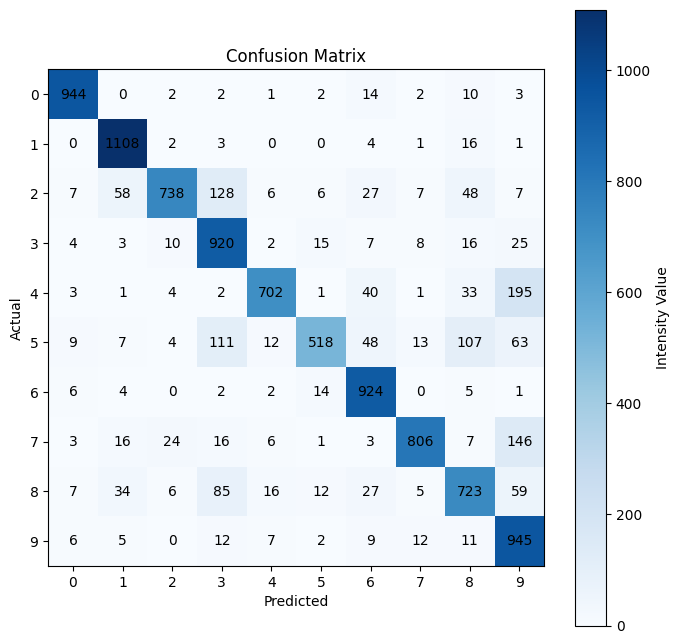

In [27]:
fig, ax = plt.subplots(figsize=(8, 8))
cax = ax.imshow(confusion_matrix, cmap="Blues")

# plt.figure(figsize=(7, 7))

plt.imshow(confusion_matrix, cmap="Blues")

# Annotate each cell with its value
for i in range(10):
    for j in range(10):
        val = confusion_matrix[i, j]
        color = "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color)

# Add colorbar and labels
plt.colorbar(label="Intensity Value")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(range(10))
plt.yticks(range(10))

plt.show()

In [28]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from metrics import calculate_per_class_metrics, calculate_overall_metrics

per_class_metrics = calculate_per_class_metrics(confusion_matrix)
overall_metrics = calculate_overall_metrics(confusion_matrix)

{'precision': array([0.95449949, 0.89644013, 0.93417722, 0.71818891, 0.93103448,
       0.90718039, 0.83771532, 0.94269006, 0.74077869, 0.65397924]), 'recall': array([0.96326531, 0.97621145, 0.71511628, 0.91089109, 0.71486762,
       0.58071749, 0.96450939, 0.78404669, 0.74229979, 0.93657086]), 'fscore': array([0.95886237, 0.93462674, 0.81009879, 0.80314273, 0.80875576,
       0.70813397, 0.89665211, 0.85608072, 0.74153846, 0.77017115])}
{'precision': 0.8518791660332464, 'recall': 0.8328, 'fscore': 0.8311941097197588}


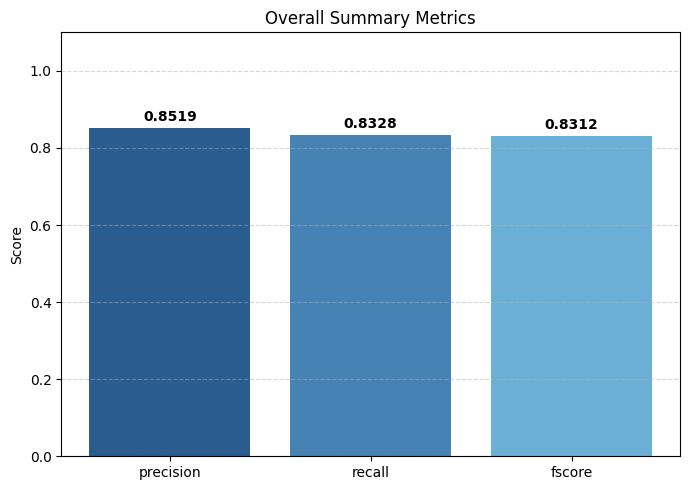

In [29]:
plt.figure(figsize=(7, 5))
bars = plt.bar(overall_metrics.keys(), overall_metrics.values(), color=['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1'])

# Annotate exact score on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

plt.ylim(0, 1.1)
plt.ylabel('Score')
plt.title('Overall Summary Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

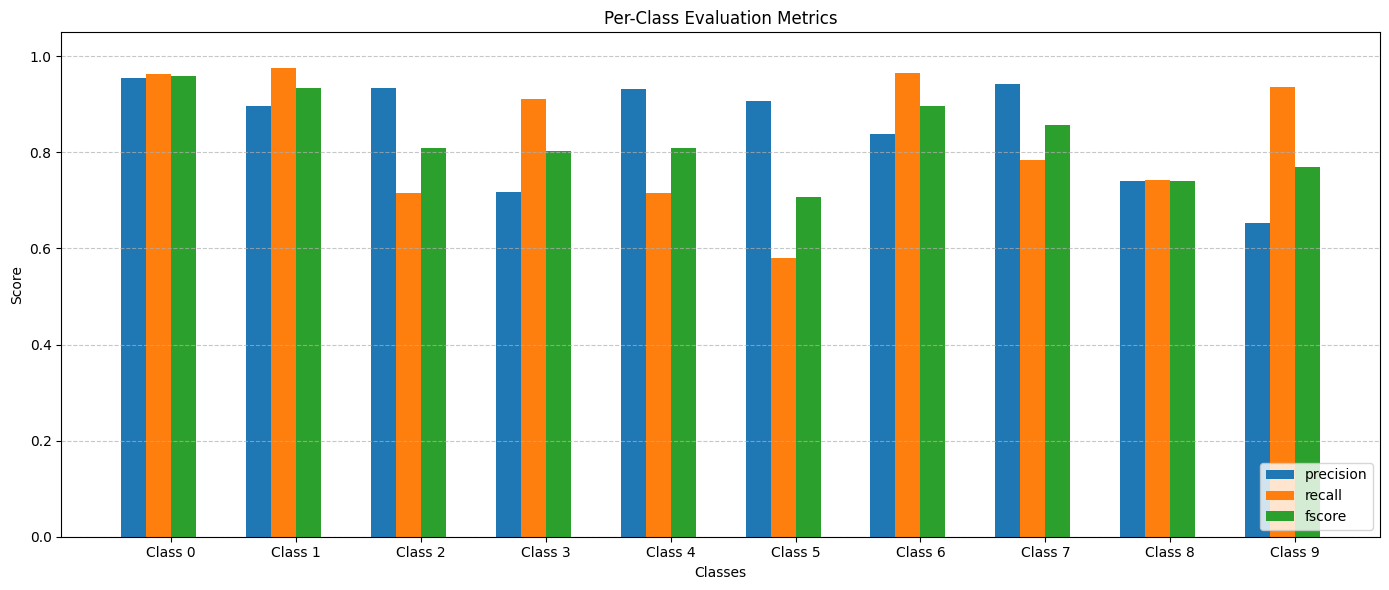

In [30]:
num_classes = len(per_class_metrics['precision'])
classes = [f'Class {i}' for i in range(num_classes)]

x = np.arange(num_classes)
width = 0.2  # Bar width

plt.figure(figsize=(14, 6))

for i, (metric, values) in enumerate(per_class_metrics.items()):
    plt.bar(x + i * width, values, width, label=metric)

plt.xlabel('Classes')
plt.ylabel('Score')
plt.title('Per-Class Evaluation Metrics')
plt.xticks(x + width * 1.5, classes)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

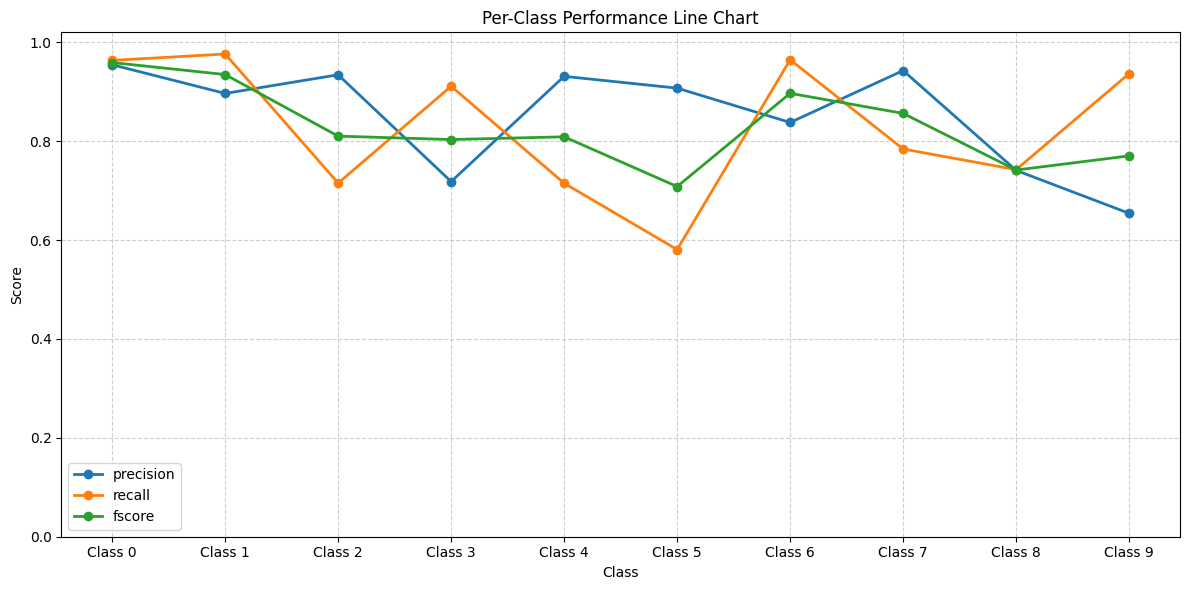

In [31]:
classes = [f'Class {i}' for i in range(10)]

plt.figure(figsize=(12, 6))

# Plot line for each metric
for metric_name, values in per_class_metrics.items():
    plt.plot(classes, values, marker='o', linewidth=2, label=metric_name)

plt.xlabel('Class')
plt.ylabel('Score')
plt.title('Per-Class Performance Line Chart')
plt.ylim(0.0, 1.02)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()


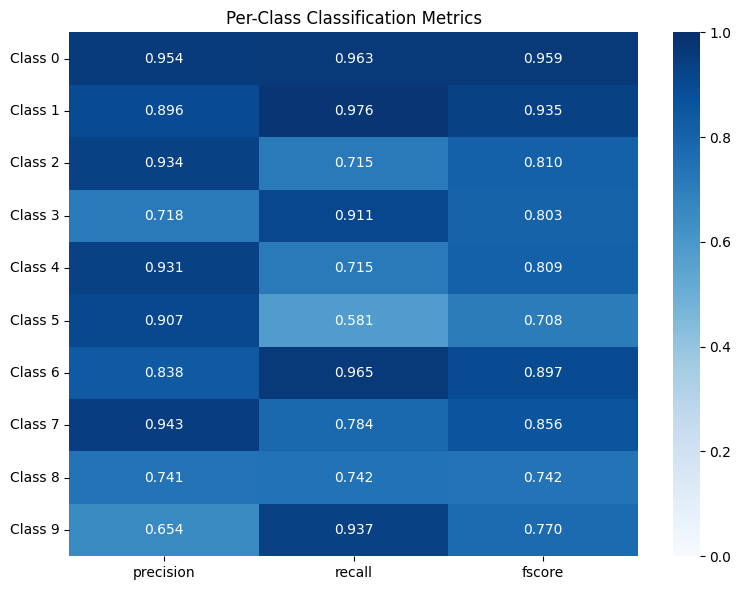

In [32]:
import pandas as pd
import seaborn as sns

df_per_class = pd.DataFrame(per_class_metrics, index=[f'Class {i}' for i in range(10)])

plt.figure(figsize=(8, 6))
sns.heatmap(df_per_class, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1)
plt.title("Per-Class Classification Metrics")
plt.tight_layout()
plt.show()

In [33]:
handmade_input3 = [
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
]

classifier.predict_argmax(handmade_input3)

3

In [34]:
handmade_input8 = [
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
]
classifier.predict_argmax(handmade_input8)

3

### Results
|Attempt|Training time|Accuracy|Description|
|-|-|-|-|
|no.1|? 177 min ?|0.7002||
|no.2|9 min 24 sec|0.8294|predict argmax + sigmoid activation|
